In [33]:
import pandas as pd
import numpy as np

df = pd.read_csv("House_Price_dataset.csv")
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished


In [34]:
df.isna().sum()

price               0
area                0
bedrooms            5
bathrooms           5
stories             2
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             4
prefarea            0
furnishingstatus    0
dtype: int64

In [35]:
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())
df["bathrooms"] = df["bathrooms"].fillna(df["bathrooms"].median())
df["stories"] = df["stories"].fillna(df["stories"].median())
df["parking"] = df["parking"].fillna(df["parking"].median())

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished


In [36]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["mainroad"] = le.fit_transform(df["mainroad"])
df["guestroom"] = le.fit_transform(df["guestroom"])
df["basement"] = le.fit_transform(df["basement"])
df["hotwaterheating"] = le.fit_transform(df["hotwaterheating"])
df["airconditioning"] = le.fit_transform(df["airconditioning"])
df["prefarea"] = le.fit_transform(df["prefarea"])


furnishing_mapping = {
    "unfurnished": 0,
    "semi-furnished": 1,
    "furnished": 2,
}

df["furnishingstatus"] = df["furnishingstatus"].map(furnishing_mapping)

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,2
1,12250000,8960,4.0,4.0,4.0,1,0,0,0,1,3.0,0,2
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,1
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,3.0,1,2
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,2


In [37]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [38]:
X_simple = df[["area"]]
y_simple = df["price"]

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=15
)

model_simple_lr = LinearRegression()
model_simple_lr.fit(X_train_simple, y_train_simple)

y_pred_simple = model_simple_lr.predict(X_test_simple)

sse_simple = np.sum((y_test_simple - y_pred_simple) ** 2)
mse_simple = np.mean((y_test_simple - y_pred_simple) ** 2)
rmse_simple = np.sqrt(mse_simple)
r2_simple = r2_score(y_test_simple, y_pred_simple)

print("--- Linear Regression (area feature only) ---")
print(f"Sum of Squared Errors (SSE): {sse_simple:.4f}")
print(f"Mean Squared Error (MSE): {mse_simple:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_simple:.4f}")
print(f"R² Score: {r2_simple:.4f}")

--- Linear Regression (area feature only) ---
Sum of Squared Errors (SSE): 315509323099537.8750
Mean Squared Error (MSE): 2894580945867.3198
Root Mean Squared Error (RMSE): 1701346.8035
R² Score: 0.2363


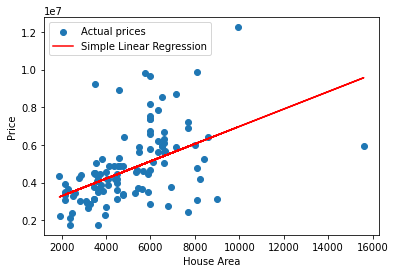

In [39]:
import matplotlib.pyplot as plt

plt.scatter(
    X_test_simple["area"],
    y_test_simple,
    label="Actual prices"
)

plt.plot(
    X_test_simple["area"].values,
    y_pred_simple,
    color="red",
    label="Simple Linear Regression"
)

plt.xlabel("House Area")
plt.ylabel("Price")
plt.legend()
plt.show()

In [40]:
X = df.drop("price", axis=1)
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=15
)

model_multi_lr = LinearRegression()
model_multi_lr.fit(X_train, y_train)

y_pred_multi = model_multi_lr.predict(X_test)

sse = np.sum((y_test - y_pred_multi) ** 2)
mse = np.mean((y_test - y_pred_multi) ** 2)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_multi)

print("--- Linear Regression (all features) ---")
print(f"Sum of Squared Errors (SSE): {sse:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

--- Linear Regression (all features) ---
Sum of Squared Errors (SSE): 151640151657415.5625
Mean Squared Error (MSE): 1391194051902.8950
Root Mean Squared Error (RMSE): 1179488.8944
R² Score: 0.6329


In [41]:
from sklearn.preprocessing import PolynomialFeatures

X = df[["area"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

poly = PolynomialFeatures(degree=3)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model_poly_lr = LinearRegression()
model_poly_lr.fit(X_train_poly, y_train)

y_pred_poly = model_poly_lr.predict(X_test_poly)

sse = np.sum((y_test - y_pred_poly) ** 2)
mse = np.mean((y_test - y_pred_poly) ** 2)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_poly)

print("--- Polynomial Regression ---")
print(f"Sum of Squared Errors (SSE): {sse:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

--- Polynomial Regression ---
Sum of Squared Errors (SSE): 388453468808959.3750
Mean Squared Error (MSE): 3563793291825.3154
Root Mean Squared Error (RMSE): 1887801.1791
R² Score: 0.2949


In [42]:
area = float(input("Enter house area: "))
bedrooms = float(input("Enter number of bedrooms: "))
bathrooms = float(input("Enter number of bathrooms: "))
stories = float(input("Enter number of stories/floors: "))
mainroad = int(input("Is the house on a main road? (1 for Yes / 0 for No): "))
guestroom = int(input("Does it have a guest room? (1 for Yes / 0 for No): "))
basement = int(input("Does it have a basement? (1 for Yes / 0 for No): "))
hotwaterheating = int(input("Does it have hot water heating? (1 for Yes / 0 for No): "))
airconditioning = int(input("Does it have air conditioning? (1 for Yes / 0 for No): "))
parking = float(input("Enter number of parking spaces: "))
prefarea = int(input("Is it located in a preferred area? (1 for Yes / 0 for No): "))
furnishingstatus = int(input("What is the furnishing status? (2 for Furnished, 1 for Semi-Furnished, 0 for Unfurnished): "))

user_data = pd.DataFrame({
    "area": [area],
    "bedrooms": [bedrooms],
    "bathrooms": [bathrooms],
    "stories": [stories],
    "mainroad": [mainroad],
    "guestroom": [guestroom],
    "basement": [basement],
    "hotwaterheating": [hotwaterheating],
    "airconditioning": [airconditioning],
    "parking": [parking],
    "prefarea": [prefarea],
    "furnishingstatus": [furnishingstatus]
})

predicted_price = model_multi_lr.predict(user_data)[0]
print("\nPredictions:")
print(f"Predicted Price: {predicted_price:,.2f}")

Enter house area: 4564
Enter number of bedrooms: 4
Enter number of bathrooms: 4
Enter number of stories/floors: 3
Is the house on a main road? (1 for Yes / 0 for No): 0
Does it have a guest room? (1 for Yes / 0 for No): 1
Does it have a basement? (1 for Yes / 0 for No): 0
Does it have hot water heating? (1 for Yes / 0 for No): 00
Does it have air conditioning? (1 for Yes / 0 for No): 1
Enter number of parking spaces: 3
Is it located in a preferred area? (1 for Yes / 0 for No): 1
What is the furnishing status? (2 for Furnished, 1 for Semi-Furnished, 0 for Unfurnished): 1

Predictions:
Predicted Price: 8,727,115.48


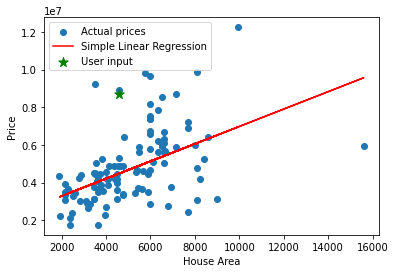

In [43]:
plt.scatter(
    X_test_simple["area"],
    y_test_simple,
    label="Actual prices"
)

plt.plot(
    X_test_simple["area"].values,
    y_pred_simple,
    color="red",
    label="Simple Linear Regression"
)

plt.scatter(area, predicted_price, color="green", marker="*", s=100, label="User input")

plt.xlabel("House Area")
plt.ylabel("Price")
plt.legend()
plt.show()